Successfully generated 50000 fab-realistic synthetic runs!

----------------------------------------
Deposition Rate Quantiles
0.10 : 5.670 nm/min
0.25 : 26.333 nm/min
0.50 : 103.535 nm/min
0.75 : 443.490 nm/min
0.90 : 1466.478 nm/min
----------------------------------------
Mean Film Non-Uniformity: 2.85 %
Defect Rate: 14.35%
----------------------------------------


,temp_C,pressure_torr,power_W,SiH4_flow_sccm,N2O_flow_sccm,Ar_flow_sccm,deposition_rate_nm/min,non_uniformity_pct,defect_label
0,306.181018,4.388946,195.194761,16.229051,708.658341,1887.829835,115.636612,3.373392,0
1,392.607146,2.978068,181.742912,62.712707,1025.617863,331.900240,39.742818,3.554535,0
2,359.799091,1.781862,137.759237,81.898187,378.587896,535.485066,79.889794,2.062067,0
3,339.798773,3.946567,173.303164,78.802579,1004.306646,1369.048015,242.079938,2.254592,0
4,273.402796,2.674713,141.274159,85.365659,565.546429,982.479654,1521.988348,3.207012,0


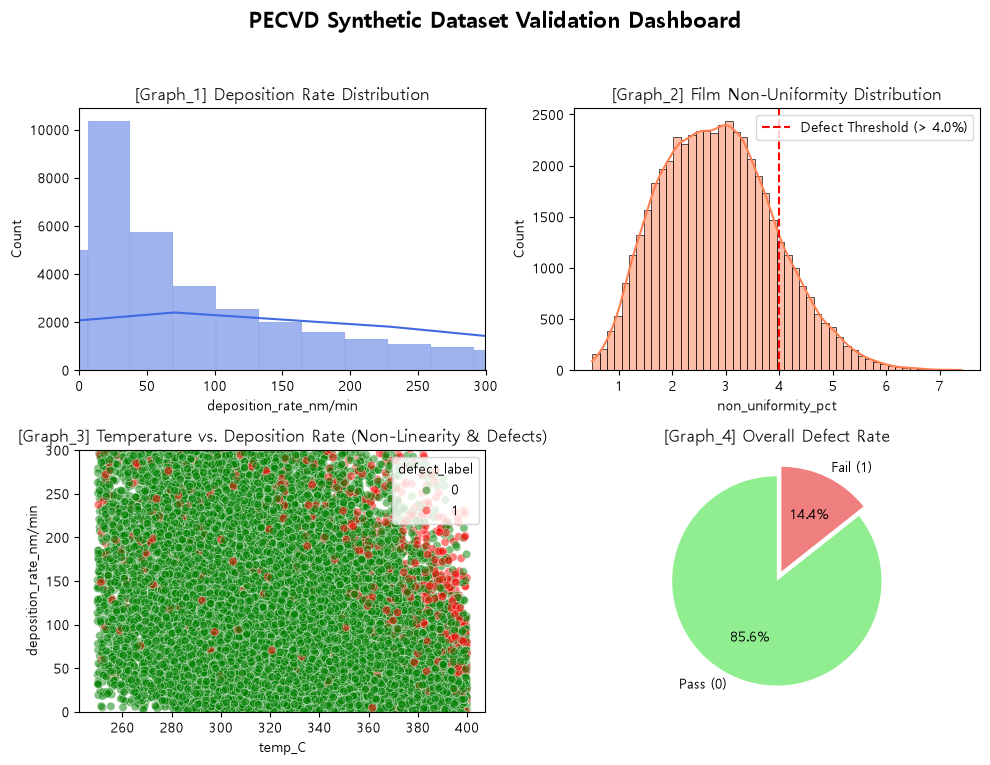

In [1]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score

# i.   Physics-Informed Synthetic Data Generation Function (50,000 Runs)
def generate_pecvd_data(n_samples=50000):
    np.random.seed(42)
    
    # [01] Random Sampling of Process Control Parameters
    temp_c = np.random.uniform(250, 400, n_samples)     # Celcius
    temp_k = temp_c + 273.15                            # Kelvin
    pressure = np.random.uniform(1, 5.0, n_samples)     # Torr
    power_w = np.random.uniform(50, 300, n_samples)     # W
    sih4_flow = np.random.uniform(10, 100, n_samples)   # sccm
    n2o_flow = np.random.uniform(200, 2000, n_samples)  # sccm
    ar_flow = np.random.uniform(200, 2000, n_samples)   # sccm
    
    # [02] Thermodynamic Constants & Radical Survival Probabilities
    R = 8.314 # Universal gas constant (J/mol·K)
    # a-1. Standard adsorption entropy change (J/(mol·K)) for SiH4 and N2O
    # a-2. Negative values reflect translational entropy loss upon surface immobilization
    sih4_dS_ads = -95.0 
    n2o_dS_ads = -115.0

    # b-1. SiH4 survival probability: accounts for gas-phase recombination & particle loss (mean 80%, ±5% std)
    sih4_prob = np.clip(np.random.normal(0.80, 0.05, n_samples), 0.5, 1.0)

    # b-2. N2O effective probability: accounts for recombination & plasma non-uniformity (mean 85%, ±5% std)
    n2o_prob = np.clip(np.random.normal(0.85, 0.05, n_samples), 0.5, 1.0)  

    # [03] Radical Generation (Bond Dissociation Energy & Probabilistic Yield)
    bde_sih4 = 378000.0      # Si-H bond dissociation energy (J/mol)
    bde_n2o = 167000.0       # N2O -> N2 + O bond dissociation energy (J/mol)
    total_flow = sih4_flow + n2o_flow + ar_flow  # Total gas flow rate (sccm)

    # [04] Dissociation Fraction Model (Mass-Energy Conservation & Penning Effect)
    # a. Energy absorbed by Ar is recycled into plasma boost & sputtering
    ar_ratio = (ar_flow / total_flow + 1e-9) 

    # b. Enhancement factor (1.0x to 2.5x) from Ar dilution/Penning excitation aiding precursor dissociation
    penning_catalyst = 1.0 + (ar_ratio * 1.5) 

    # c. RF power delivered per molar gas feed rate (7.436e-7 converts sccm to mol/s at STP)
    specific_energy = power_w / (total_flow * 7.436e-7)

    # d. Fractional dissociation (0 to 1) of SiH4 and N2O via saturating energy-to-BDE ratio
    alpha_sih4 = 1.0 - np.exp(-(specific_energy / bde_sih4) * penning_catalyst)
    alpha_n2o = 1.0 - np.exp(-(specific_energy / bde_n2o) * penning_catalyst)

    # [05] Net Radical Generation Rate (mol/s) & Radical Partial Pressures (atm)
    # a. Effective reactive radical molar flux after dissociation and survival/recombination loss
    sih4_radical = sih4_flow * 7.436e-7 * alpha_sih4 * sih4_prob 
    n2o_radical = n2o_flow * 7.436e-7 * alpha_n2o * n2o_prob     

    # [06] Argon (Ar) Dual Effect: Dilution vs. Penning Ionization Boost
    # a. Total molar flow (mol/s) including newly formed dissociated species
    total_radical = total_flow * 7.436e-7 + (sih4_flow * 7.436e-7 * alpha_sih4) + (n2o_flow * 7.436e-7 * alpha_n2o)
    
    # b. Radical partial pressures (1 atm = 760 Torr) based on mole fraction
    p_radical_sih4 = (pressure / 760)* (sih4_radical / total_radical)
    p_radical_n2o = (pressure / 760)* (n2o_radical / total_radical)
    
    # [07] Van 't Hoff Equation: Chemisorption Equilibrium Constants (K)
    # a-1. Practical PECVD occurs on H-terminated surfaces with multi-species competitive adsorption.
    # a-2. Effective adsorption energies are used here to reflect realistic surface coverage and prevent rate overestimation.
    Q_ads_sih4 = 45000.0                # Effective heat of chemisorption for SiH4 radicals (J/mol)
    Q_ads_n2o = 65000.0                 # Effective heat of chemisorption for N2O/O radicals (J/mol)
    K_0_sih4 = np.exp(sih4_dS_ads / R ) # Entropic pre-exponential factor for SiH4 adsorption equilibrium
    K_0_n2o = np.exp(n2o_dS_ads / R )   # Entropic pre-exponential factor for N2O adsorption equilibrium

    # b. Temperature-dependent adsorption equilibrium constants (lower T favors exothermic adsorption)
    k_ads_sih4 = K_0_sih4 * np.exp(Q_ads_sih4 / (R * temp_k))
    k_ads_n2o = K_0_n2o * np.exp(Q_ads_n2o / (R * temp_k))

    # [08] Langmuir-Hinshelwood (L-H) Surface Reaction Kinetics
    # a. Squared denominator accounts for two-site surface reaction between adsorbed Si- and O-containing species
    denominator = (1.0 + k_ads_sih4 * p_radical_sih4 + k_ads_n2o * p_radical_n2o)**2
    
    # b. Normalized surface reaction rate term capturing competitive site occupancy and Langmuir saturation
    lh_surface_term = (k_ads_sih4 * p_radical_sih4 * k_ads_n2o * p_radical_n2o) / denominator
    
    # [09] Surface Reaction Rate Constant (Low Ea for Pre-activated Plasma Radicals)
    Ea_radical = 10000.0                   # Activation energy (J/mol) 
    A_factor = 2.2e12                      # Pre-exponential factor incorporating nm/min unit conversion
    k_surface = A_factor * np.exp(-Ea_radical / (R * temp_k)) # Arrhenius surface reaction rate constant
    
    # [10] Deposition Rate Assembly: Gross Growth, Ar Sputtering Loss & Residence Time
    # a. Gross chemical deposition rate before physical sputtering and gas residence effects
    gross_deposition_rate = k_surface * lh_surface_term

    # b-1. Ar ion sputtering etch loss (physical bombardment penalty)
    # b-2. Scales linearly with RF power and Ar mole fraction; floored at zero to prevent negative growth
    ar_etch_rate = 1.5 * (power_w / 150.0) * (ar_flow / total_flow)
    sputtered_rate = np.maximum(0.0, gross_deposition_rate - ar_etch_rate)

    # c-1. Residence time (tau) trade-off in a 30L reactor
    chamber_volume_L = 30.0                      # Effective reactor volume (L)

    # c-2. Convert total sccm flow to actual volumetric flow rate (L/s) at reactor pressure and temperature
    q_actual = (total_flow / 1000.0) * (760.0 / pressure) * (temp_k / 273.15)
    tau = chamber_volume_L / (q_actual + 1e-9)   # Mean gas residence time (s) inside the chamber

    # c-3. Longer residence time increases reaction opportunity but raises gas-phase depletion/recombination loss
    opportunity_factor = 1.0 - np.exp(-1.5 * tau * 60.0)
    loss_sih4 = np.exp(-0.1 * tau * 60.0)
    loss_n2o = np.exp(-0.05 * tau * 60.0)
    tau_efficiency = opportunity_factor * loss_sih4 * loss_n2o  # Net residence-time transport efficiency
    final_deposition_rate = np.maximum(0.0, sputtered_rate * tau_efficiency)

    # [11] Industrial Fab Realism: Unobserved Confounders & Heteroscedastic Noise
    # a-1. Cumulative chamber wall condition (unobserved latent variable excluded from ML features)
    # a-2. Simulates run-to-run wall coating/seasoning drift (~±10% std) that causes irreducible ML prediction error
    chamber_wall_condition = np.random.normal(1.0, 0.10, n_samples) 
    
    # b-1. Heteroscedastic noise: variance scales with temperature and RF power (extreme process regimes)
    # b-2. Captures higher process instability and plasma fluctuation under aggressive thermal/power conditions
    extreme_scale = ((temp_c - 250) / 100.0) * (power_w / 150.0)
    hetero_noise = np.random.normal(0, 10.0, n_samples) * extreme_scale 
    
    # c. Final observed deposition rate (nm/min) combining latent wall drift and heteroscedastic noise
    dep_rate = (final_deposition_rate * chamber_wall_condition) + hetero_noise    

    # [12] Film Non-Uniformity (%) & Defect Labeling (45:35:20 Weighting)
    # a. Pressure effect (45% weight): diffusion gradient intensifies at high pressure
    pressure_norm = pressure / 2.0
    pressure_effect = 0.45 * np.power(pressure_norm, 1.5)

    # b. Ar flow effect (35% weight): low Ar flow causes center precursor depletion
    ar_effect = 0.35 * 900.0 / (ar_flow + 1e-9) 

    # c. RF power effect (20% weight): edge-ring plasma sheath non-uniformity
    power_effect = 0.20 * (power_w / 120.0 )

    # d-1. Thermal deviation penalty (centered at 350 °C)
    # d-2. Quadratic penalty as wafer temperature deviates from the nominal 350 °C sweet spot
    temp_effect = np.square(temp_c - 350.0) * 0.0002

    # e. Base non-uniformity calculation combining weighted physical terms and thermal offset
    uniformity_base = 1.5 * (pressure_effect + ar_effect + power_effect) + temp_effect
    
    # f. Add Gaussian measurement noise and clip to physical bounds (0.5% - 10.0%)
    noise_uni = np.random.normal(0, 0.3, n_samples)
    non_uniformity_pct = np.clip(uniformity_base + noise_uni, 0.5, 10.0)

    # g. Defect classification: Defect = 1 if non-uniformity exceeds 4.0% (target defect rate 10~15%)
    defect_label = np.where(non_uniformity_pct > 4.0, 1, 0)

    # [13] Assemble final DataFrame
    df = pd.DataFrame({
        'temp_C': temp_c, 'pressure_torr': pressure, 'power_W': power_w,
        'SiH4_flow_sccm': sih4_flow, 'N2O_flow_sccm': n2o_flow, 'Ar_flow_sccm': ar_flow,
        'deposition_rate_nm/min': dep_rate,
        'non_uniformity_pct': non_uniformity_pct,
        'defect_label': defect_label
    })
    return df

# ii.  Execute simulation function to generate synthetic dataset
df = generate_pecvd_data(n_samples=50000)

# iii. Export dataset to CSV without row indices
file_name = "Dataset_sample.csv"
df.to_csv(file_name, index=False)

# iv.  Print summary statistics (ensure column names match DataFrame schema)
print(f"Successfully generated {len(df)} fab-realistic synthetic runs!\n")
print("-" * 40)
quantiles = df['deposition_rate_nm/min'].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
print("Deposition Rate Quantiles")
for q, val in quantiles.items():
    print(f"{q:.2f} : {val:.3f} nm/min")
print("-" * 40)
print(f"Mean Film Non-Uniformity: {df['non_uniformity_pct'].mean():.2f} %")
print(f"Defect Rate: {(df['defect_label'].mean() * 100):.2f}%")
print("-" * 40)

# v.   Preview first five rows of the generated dataset
display(df.head())  

# vi.  Configure font settings (fallback to standard sans-serif if Malgun Gothic is unavailable on Linux/GitHub)
plt.rcParams['font.family'] = 'Malgun Gothic' 
plt.rcParams['axes.unicode_minus'] = False

# vii. Diagnostic Visualization Function for Synthetic PECVD Dataset Validation
def plot_data_distribution(df):
    # [1] Create 2x2 diagnostic dashboard for synthetic data validation
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    fig.suptitle('PECVD Synthetic Dataset Validation Dashboard', fontsize=16, fontweight='bold')

    # [2] Deposition rate distribution (Histogram with KDE overlay)
    sns.histplot(data=df, x='deposition_rate_nm/min', bins=1000, kde=True, color='royalblue', ax=axes[0, 0])
    axes[0, 0].set_title('[Graph_1] Deposition Rate Distribution')
    axes[0, 0].set_xlim(0, 300) # Clip x-axis to 0-300 nm/min for clear view of main regime

    # [3] Film non-uniformity distribution with defect threshold line
    sns.histplot(data=df, x='non_uniformity_pct', bins=50, kde=True, color='coral', ax=axes[0, 1])
    axes[0, 1].axvline(x=4.0, color='red', linestyle='--', label='Defect Threshold (> 4.0%)')
    axes[0, 1].set_title('[Graph_2] Film Non-Uniformity Distribution')
    axes[0, 1].legend()

    # [4] Temperature vs. deposition rate scatter colored by defect status
    sns.scatterplot(data=df, x='temp_C', y='deposition_rate_nm/min', hue='defect_label', 
                    palette={0: 'green', 1: 'red'}, alpha=0.5, ax=axes[1, 0])
    axes[1, 0].set_title('[Graph_3] Temperature vs. Deposition Rate (Non-Linearity & Defects)')
    axes[1, 0].set_ylim(0, 300)  # Clip y-axis to 0-300 nm/min to inspect core trend

    # [5] Pass vs. fail ratio pie chart (defensive mapping handles single-class edge cases)
    # a. Map class indices dynamically to prevent KeyError if only 0 or 1 is present
    defect_counts = df['defect_label'].value_counts()
    labels_map = {0: 'Pass (0)', 1: 'Fail (1)'}
    colors_map = {0: 'lightgreen', 1: 'lightcoral'}
    current_labels = [labels_map[k] for k in defect_counts.index]
    current_colors = [colors_map[k] for k in defect_counts.index]
    explode = [0.1 if i == len(defect_counts) - 1 else 0 for i in range(len(defect_counts))]
    axes[1, 1].pie(defect_counts, labels=current_labels, autopct='%1.1f%%', 
                   colors=current_colors, startangle=90, explode=explode)
    axes[1, 1].set_title('[Graph_4] Overall Defect Rate')

    # [6] Print Graphs
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

plot_data_distribution(df)